# CDD109 – Redes Neurais Artificiais e Deep Learning
# Projeto 3 – Detecção de Falhas em Placas de Aço

**Integrantes:**
- Leonardo Isaac Silva Flores
- Eduardo Alexandre Sobreira

**Objetivo:** ao final deste projeto somos capazes de (i) preparar uma base de dados real para uma rede neural, separando os dados em treino e teste e normalizando as variáveis; (ii) projetar, treinar e avaliar uma rede neural MLP no Keras para um problema de classificação com várias classes; (iii) investigar como a escolha dos parâmetros da rede (camadas, neurônios, ativação, otimizador etc.) altera o desempenho; (iv) interpretar os resultados com a matriz de confusão; e (v) reconhecer o efeito de uma base de dados desbalanceada sobre o aprendizado.

Neste projeto utilizamos a base de dados *Steel Plates Faults*, disponibilizada pela Semeion Research Center of Sciences of Communication e publicada no Kaggle em https://www.kaggle.com/uciml/faulty-steel-plates. A base possui 1941 amostras e 34 colunas: as 27 primeiras colunas descrevem a forma geométrica da falha e seu contorno, e as 7 últimas colunas correspondem ao rótulo do defeito (codificado no padrão *One-Hot*), existindo seis tipos de defeito e um sétimo tipo considerado "outros defeitos" (`Other_Faults`).

O arquivo `faults.csv`, já no formato de 34 colunas descrito no enunciado, foi baixado do Kaggle/UCI e colocado na mesma pasta deste notebook (ao invés de montar o Google Drive, como sugerido para o Google Colab).

## Etapa 01
Importar as bibliotecas de computação científica, pré-processamento e aprendizado de máquina.

In [1]:
# Bibliotecas de manipulacao e visualizacao de dados
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Bibliotecas de pre-processamento e particionamento dos dados
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.decomposition import PCA

# Bibliotecas de avaliacao do modelo
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

# Biblioteca para balanceamento de classes (Desafio 1)
from imblearn.over_sampling import SMOTE

# Bibliotecas de redes neurais (Keras)
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Input
from keras.optimizers import Adam, SGD, RMSprop
from keras.utils import to_categorical

np.random.seed(42)

## Etapa 02
Carregar a base de dados `faults.csv`. A variável `my_data` contém todos os dados (1941 linhas x 34 colunas); a primeira linha do arquivo é o cabeçalho com o nome das colunas, por isso usamos `skip_header=1`.

In [2]:
# Endereco da base de dados (arquivo faults.csv esta na mesma pasta deste notebook)
path_database = 'faults.csv'

# Carregando o dado na matriz my_data
my_data = np.genfromtxt(path_database, delimiter=',', skip_header=1)

print('Formato da base de dados (my_data):', my_data.shape)

Formato da base de dados (my_data): (1941, 34)


## Etapa 03
Salvar nas matrizes `X` e `Y` as características e os rótulos. As primeiras 27 colunas de `my_data` correspondem às 27 características extraídas das falhas das placas de aço (`X`), e as últimas 7 colunas correspondem aos rótulos no padrão *One-Hot* (`Y`).

In [3]:
# Salvando os dados e os rotulos
X = my_data[:, 0:27]
Y = my_data[:, 27:34]

nomes_falhas = ['Pastry', 'Z_Scratch', 'K_Scratch', 'Stains',
                'Dirtiness', 'Bumps', 'Other_Faults']

print('X:', X.shape)
print('Y:', Y.shape)

X: (1941, 27)
Y: (1941, 7)


## Etapa 04 — Questão 1
Realizar a contagem de quantas amostras há para cada tipo de falha e verificar se a base de dados é balanceada.

In [4]:
contagem_falhas = Y.sum(axis=0).astype(int)
total_amostras = len(Y)

tabela_contagem = pd.DataFrame({
    'Falha': nomes_falhas,
    'Quantidade': contagem_falhas,
    'Proporcao (%)': np.round(100 * contagem_falhas / total_amostras, 2)
})
tabela_contagem

,Falha,Quantidade,Proporcao (%)
0,Pastry,158,8.14
1,Z_Scratch,190,9.79
2,K_Scratch,391,20.14
3,Stains,72,3.71
4,Dirtiness,55,2.83
5,Bumps,402,20.71
6,Other_Faults,673,34.67


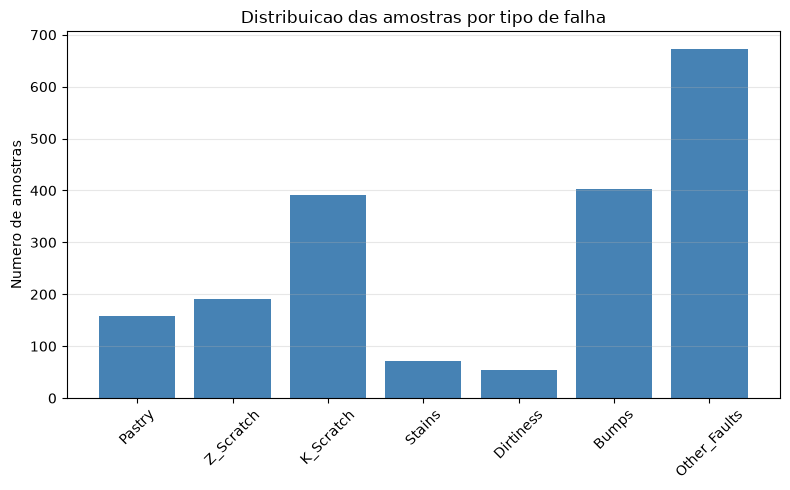

In [5]:
plt.figure(figsize=(8, 5))
plt.bar(nomes_falhas, contagem_falhas, color='steelblue')
plt.ylabel('Numero de amostras')
plt.title('Distribuicao das amostras por tipo de falha')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Resposta:** não, a base de dados não é balanceada. A falha `Other_Faults` é a mais comum, com 673 das 1941 amostras (34,7%). Já `Dirtiness` tem só 55 amostras (2,8%) e `Stains` tem 72 (3,7%) — ou seja, a classe mais comum aparece mais de 12 vezes mais do que as mais raras. `K_Scratch` (391, 20,1%) e `Bumps` (402, 20,7%) também têm bastante amostra, enquanto `Pastry` (158, 8,1%) e `Z_Scratch` (190, 9,8%) ficam no meio do caminho.

Esse desbalanceamento é um risco para o treinamento: como a rede ajusta seus pesos tentando errar o mínimo possível no total de amostras, ela tende a aprender melhor os padrões das classes com mais exemplos e pode "esquecer" as classes raras, que contribuem com poucos exemplos durante o treino. Na prática, isso pode fazer a acurácia geral parecer boa mesmo que o modelo erre bastante em algumas classes, já que elas pesam pouco no cálculo da acurácia total. Vamos conferir se isso realmente aconteceu quando analisarmos a matriz de confusão do melhor modelo, na Questão 5.

## Etapa 05
Particionar aleatoriamente 70% das amostras para treinar a rede neural MLP e os 30% restantes para validar o sistema.

In [6]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, random_state=42)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('Y_train:', Y_train.shape)
print('Y_test :', Y_test.shape)

X_train: (1358, 27)
X_test : (583, 27)
Y_train: (1358, 7)
Y_test : (583, 7)


## Etapa 06
Normalizar as entradas de dados para que assumam valores entre 0 e 1. O normalizador é ajustado (`fit`) apenas com os dados de treino e, depois, apenas aplicado (`transform`) aos dados de teste, para que nenhuma informação do teste influencie o treinamento.

In [7]:
min_max_scaler = preprocessing.MinMaxScaler(feature_range=(0, 1))
X_train = min_max_scaler.fit_transform(X_train)
X_test = min_max_scaler.transform(X_test)

## Etapa 07
Construir a rede neural MLP no Keras. Para facilitar a investigação feita na Questão 3 (variação dos parâmetros), criamos a função `cria_modelo_mlp`, que recebe como parâmetros o número de camadas ocultas, o número de neurônios por camada, a função de ativação, o otimizador e a taxa de aprendizado, e devolve um modelo Keras já compilado.

In [8]:
def cria_modelo_mlp(camadas=1, neuronios=32, ativacao='relu', otimizador='adam',
                     taxa_aprendizado=0.001, input_dim=27):
    keras.backend.clear_session()

    model = Sequential()
    model.add(Input(shape=(input_dim,)))
    for _ in range(camadas):
        model.add(Dense(neuronios, activation=ativacao))
    model.add(Dense(7, activation='softmax'))

    if otimizador == 'adam':
        opt = Adam(learning_rate=taxa_aprendizado)
    elif otimizador == 'sgd':
        opt = SGD(learning_rate=taxa_aprendizado)
    elif otimizador == 'rmsprop':
        opt = RMSprop(learning_rate=taxa_aprendizado)
    else:
        opt = otimizador

    model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    return model

Com a função definida, construímos o modelo-base (1 camada oculta com 32 neurônios, ativação ReLU, otimizador Adam) e treinamos a rede, acompanhando a evolução da acurácia de treino e de validação.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,127 (4.40 KB)

 Trainable params: 1,127 (4.40 KB)

 Non-trainable params: 0 (0.00 B)

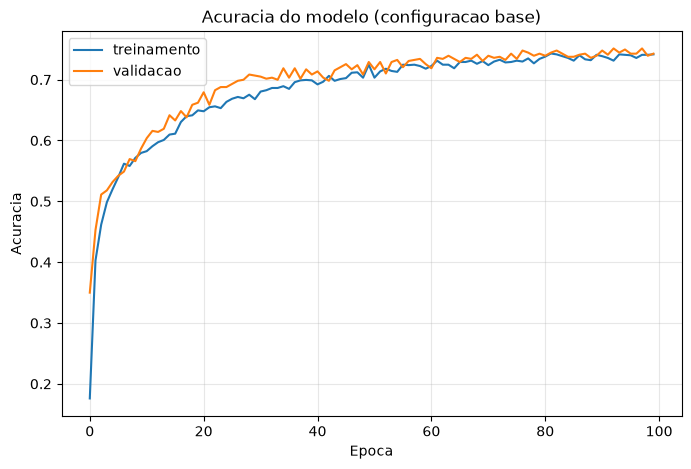

In [9]:
model = cria_modelo_mlp()
model.summary()

history = model.fit(X_train, Y_train, epochs=100, batch_size=32,
                     validation_data=(X_test, Y_test), verbose=0)

plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='treinamento')
plt.plot(history.history['val_accuracy'], label='validacao')
plt.title('Acuracia do modelo (configuracao base)')
plt.xlabel('Epoca')
plt.ylabel('Acuracia')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Etapa 08
Avaliar a acurácia da rede neural MLP projetada com a função `evaluate`.

In [10]:
# Avaliando o desempenho da rede neural MLP
desempenho = model.evaluate(X_test, Y_test, verbose=0)
print("Acuracia: %.2f%%" % (desempenho[1] * 100))

Acuracia: 74.27%


## Etapa 09
A acurácia fornece apenas uma medida global de desempenho. Para saber quais falhas a rede acerta e quais ela confunde entre si, calculamos e plotamos a matriz de confusão do conjunto de teste, além do relatório de classificação (precisão, recall e F1-score por classe).

 1/19 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


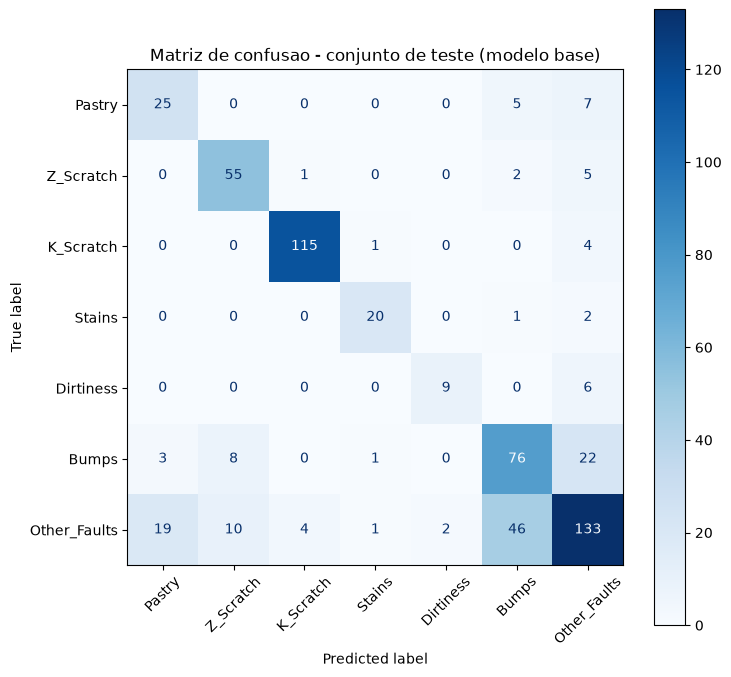

              precision    recall  f1-score   support

      Pastry       0.53      0.68      0.60        37
   Z_Scratch       0.75      0.87      0.81        63
   K_Scratch       0.96      0.96      0.96       120
      Stains       0.87      0.87      0.87        23
   Dirtiness       0.82      0.60      0.69        15
       Bumps       0.58      0.69      0.63       110
Other_Faults       0.74      0.62      0.68       215

    accuracy                           0.74       583
   macro avg       0.75      0.76      0.75       583
weighted avg       0.75      0.74      0.74       583



In [11]:
# A saida da rede e um vetor de 7 probabilidades; pegamos a classe
# de maior probabilidade. Os rotulos One-Hot tambem sao convertidos
# para o indice da classe.
Y_pred = model.predict(X_test)
y_pred = np.argmax(Y_pred, axis=1)
y_true = np.argmax(Y_test, axis=1)

# Matriz de confusao (linhas = classe real, colunas = classe prevista)
cm = confusion_matrix(y_true, y_pred, labels=range(7))

fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=nomes_falhas)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45)
plt.title('Matriz de confusao - conjunto de teste (modelo base)')
plt.show()

# Precisao, recall e F1 por classe
print(classification_report(y_true, y_pred, labels=range(7),
                             target_names=nomes_falhas, zero_division=0))

## Questão 2
Os parâmetros da rede neural MLP que podem ser variados para alterar o desempenho do classificador incluem:

- **Número de camadas** ocultas — redes mais profundas podem capturar relações mais complexas, mas também são mais propensas a *overfitting* em bases pequenas como esta (1941 amostras).
- **Número de neurônios** por camada — define a capacidade da rede de representar fronteiras de decisão mais ou menos complexas.
- **Função de ativação** (ReLU, tanh, sigmoid etc.) — altera a forma como os neurônios combinam as entradas e pode afetar a velocidade de convergência do treinamento.
- **Modelos da função de perda e de otimização** (Adam, SGD, RMSprop etc.) — alteram a forma como os gradientes são usados para atualizar os pesos da rede, impactando a velocidade e a estabilidade do treinamento.
- **Taxa de aprendizado** — controla o tamanho do passo dado a cada atualização de pesos; taxas muito altas podem fazer o treinamento divergir, e taxas muito baixas podem tornar o aprendizado lento ou ficar preso em mínimos locais.
- Outros parâmetros possíveis: número de épocas, tamanho do lote (*batch size*), uso de regularização (*dropout*, *L2*), etc.

Na Questão 3, a seguir, variamos um parâmetro por vez (camadas, neurônios, ativação, otimizador e taxa de aprendizado) para observar isoladamente o efeito de cada escolha sobre a acurácia.

## Etapa 10 — Questão 3
Testamos 6 configurações diferentes da rede MLP, alterando um parâmetro por vez em relação à configuração base (C1), para identificar qual mudança causa qual efeito no desempenho de classificação.

In [12]:
configuracoes = [
    {'config': 'C1 - Base',                   'camadas': 1, 'neuronios': 32, 'ativacao': 'relu', 'otimizador': 'adam',    'taxa_aprendizado': 0.001},
    {'config': 'C2 - Duas camadas ocultas',    'camadas': 2, 'neuronios': 32, 'ativacao': 'relu', 'otimizador': 'adam',    'taxa_aprendizado': 0.001},
    {'config': 'C3 - Mais neuronios (64)',     'camadas': 1, 'neuronios': 64, 'ativacao': 'relu', 'otimizador': 'adam',    'taxa_aprendizado': 0.001},
    {'config': 'C4 - Ativacao tanh',           'camadas': 1, 'neuronios': 32, 'ativacao': 'tanh', 'otimizador': 'adam',    'taxa_aprendizado': 0.001},
    {'config': 'C5 - Otimizador SGD',          'camadas': 1, 'neuronios': 32, 'ativacao': 'relu', 'otimizador': 'sgd',     'taxa_aprendizado': 0.001},
    {'config': 'C6 - Taxa de aprendizado 10x', 'camadas': 1, 'neuronios': 32, 'ativacao': 'relu', 'otimizador': 'adam',    'taxa_aprendizado': 0.01},
]

resultados = []
for cfg in configuracoes:
    modelo_cfg = cria_modelo_mlp(camadas=cfg['camadas'], neuronios=cfg['neuronios'],
                                  ativacao=cfg['ativacao'], otimizador=cfg['otimizador'],
                                  taxa_aprendizado=cfg['taxa_aprendizado'])
    modelo_cfg.fit(X_train, Y_train, epochs=100, batch_size=32, verbose=0)
    desempenho_cfg = modelo_cfg.evaluate(X_test, Y_test, verbose=0)
    resultados.append({**cfg, 'acuracia': desempenho_cfg[1]})
    print(f"{cfg['config']:28s} -> acuracia = {desempenho_cfg[1]*100:.2f}%")

tabela_resultados = pd.DataFrame(resultados)
tabela_resultados['acuracia (%)'] = (tabela_resultados['acuracia'] * 100).round(2)
tabela_resultados[['config', 'camadas', 'neuronios', 'ativacao', 'otimizador', 'taxa_aprendizado', 'acuracia (%)']]

C1 - Base                    -> acuracia = 74.61%


C2 - Duas camadas ocultas    -> acuracia = 74.61%


C3 - Mais neuronios (64)     -> acuracia = 74.96%


C4 - Ativacao tanh           -> acuracia = 73.93%


C5 - Otimizador SGD          -> acuracia = 51.46%


C6 - Taxa de aprendizado 10x -> acuracia = 75.99%


,config,camadas,neuronios,ativacao,otimizador,taxa_aprendizado,acuracia (%)
0,C1 - Base,1,32,relu,adam,0.001,74.61
1,C2 - Duas camadas ocultas,2,32,relu,adam,0.001,74.61
2,C3 - Mais neuronios (64),1,64,relu,adam,0.001,74.96
3,C4 - Ativacao tanh,1,32,tanh,adam,0.001,73.93
4,C5 - Otimizador SGD,1,32,relu,sgd,0.001,51.46
5,C6 - Taxa de aprendizado 10x,1,32,relu,adam,0.010,75.99


**Discussão:** comparando cada configuração com a configuração base (C1 = 74,61%), dá para ver o efeito de cada mudança:

- **C2 (duas camadas ocultas, 74,61%):** colocar uma segunda camada escondida não mudou a acurácia. Com só ~1360 amostras de treino, uma única camada de 32 neurônios já dava conta do problema, e a camada extra não ajudou nem atrapalhou.
- **C3 (64 neurônios, 74,96%):** dobrar o número de neurônios da camada melhorou um pouco (0,35 ponto percentual a mais que a base), mostrando que ainda havia espaço para a rede aprender mais com mais neurônios.
- **C4 (ativação tanh, 73,93%):** trocar a ReLU pela tanh piorou um pouco o resultado (0,68 ponto percentual a menos), sugerindo que a ReLU se encaixa um pouco melhor neste problema.
- **C5 (otimizador SGD, 51,46%):** de longe o pior resultado, caindo mais de 23 pontos percentuais em relação à base. O SGD "puro" (sem os ajustes automáticos que o Adam usa) aprende bem mais devagar, e em 100 épocas não deu tempo de a rede aprender direito os padrões da base — mostrando como a escolha do otimizador pode fazer muita diferença.
- **C6 (taxa de aprendizado 10x maior, 75,99%):** foi a melhor de todas (1,38 ponto percentual a mais que a base). Isso mostra que a taxa de aprendizado padrão do Adam (0,001) estava conservadora demais para este problema, e aumentá-la para 0,01 acelerou o aprendizado sem deixar o treino instável.

A configuração **C6** (1 camada escondida, 32 neurônios, ativação ReLU, otimizador Adam, taxa de aprendizado 0,01) foi escolhida como o "melhor caso" para as próximas etapas.

## Etapa 11 — Questão 4
Com a melhor configuração encontrada na Questão 3, definimos a função `cria_modelo()` (sem argumentos, pronta para ser reaproveitada nos desafios) e rodamos o treinamento 5 vezes, deixando a partição de dados aleatória a cada execução, para calcular a média e o desvio padrão da acurácia.

In [13]:
melhor_cfg = tabela_resultados.loc[tabela_resultados['acuracia'].idxmax()]
print('Melhor configuracao encontrada:')
print(melhor_cfg[['config', 'camadas', 'neuronios', 'ativacao', 'otimizador', 'taxa_aprendizado', 'acuracia (%)']])


def cria_modelo():
    # rede nova, sem treino anterior, com a melhor configuracao encontrada na Questao 3
    return cria_modelo_mlp(camadas=int(melhor_cfg['camadas']),
                            neuronios=int(melhor_cfg['neuronios']),
                            ativacao=melhor_cfg['ativacao'],
                            otimizador=melhor_cfg['otimizador'],
                            taxa_aprendizado=melhor_cfg['taxa_aprendizado'])

Melhor configuracao encontrada:
config              C6 - Taxa de aprendizado 10x
camadas                                        1
neuronios                                     32
ativacao                                    relu
otimizador                                  adam
taxa_aprendizado                            0.01
acuracia (%)                               75.99
Name: 5, dtype: object


In [14]:
acuracias_melhor_caso = []
for i in range(5):
    X_tr, X_te, Y_tr, Y_te = train_test_split(X, Y, test_size=0.30)

    mm = preprocessing.MinMaxScaler(feature_range=(0, 1))
    X_tr = mm.fit_transform(X_tr)
    X_te = mm.transform(X_te)

    modelo_i = cria_modelo()
    modelo_i.fit(X_tr, Y_tr, epochs=100, batch_size=32, verbose=0)
    desempenho_i = modelo_i.evaluate(X_te, Y_te, verbose=0)
    acuracias_melhor_caso.append(desempenho_i[1])
    print(f'Execucao {i + 1}: acuracia = {desempenho_i[1] * 100:.2f}%')

media_acuracia = np.mean(acuracias_melhor_caso)
desvio_acuracia = np.std(acuracias_melhor_caso)
print(f'\nAcuracia media : {media_acuracia * 100:.2f}%')
print(f'Desvio padrao  : {desvio_acuracia * 100:.2f}%')

Execucao 1: acuracia = 76.16%


Execucao 2: acuracia = 73.93%


Execucao 3: acuracia = 74.10%


Execucao 4: acuracia = 75.30%


Execucao 5: acuracia = 73.76%

Acuracia media : 74.65%
Desvio padrao  : 0.93%


## Etapa 12 — Questão 5
Analisamos a matriz de confusão do melhor caso, treinando a melhor configuração na partição de treino/teste original (Etapa 05/06), para identificar quais falhas são mais bem classificadas e quais são mais confundidas entre si.

Acuracia (melhor configuracao): 72.38%
 1/19 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


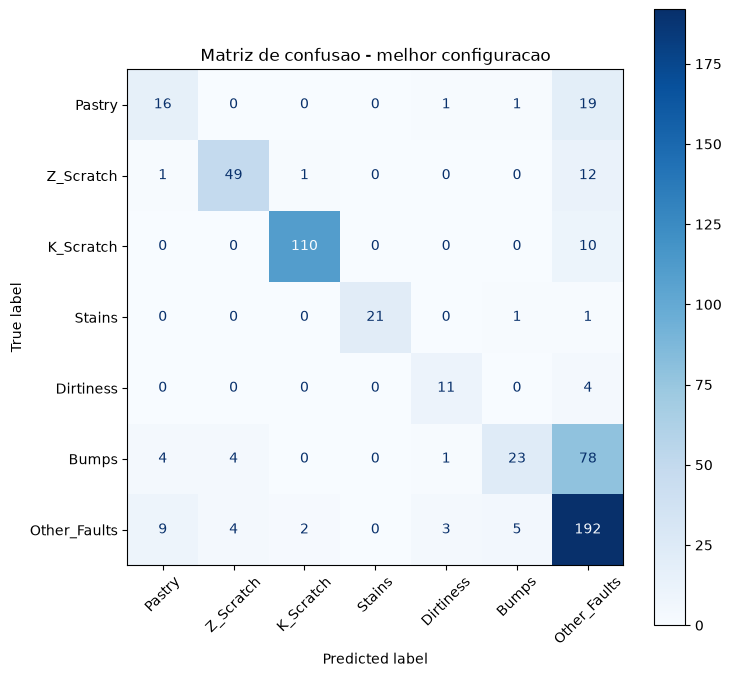

              precision    recall  f1-score   support

      Pastry       0.53      0.43      0.48        37
   Z_Scratch       0.86      0.78      0.82        63
   K_Scratch       0.97      0.92      0.94       120
      Stains       1.00      0.91      0.95        23
   Dirtiness       0.69      0.73      0.71        15
       Bumps       0.77      0.21      0.33       110
Other_Faults       0.61      0.89      0.72       215

    accuracy                           0.72       583
   macro avg       0.78      0.70      0.71       583
weighted avg       0.75      0.72      0.70       583



In [15]:
model_melhor = cria_modelo()
model_melhor.fit(X_train, Y_train, epochs=100, batch_size=32, verbose=0)

desempenho_melhor = model_melhor.evaluate(X_test, Y_test, verbose=0)
print("Acuracia (melhor configuracao): %.2f%%" % (desempenho_melhor[1] * 100))

Y_pred = model_melhor.predict(X_test)
y_pred = np.argmax(Y_pred, axis=1)
y_true = np.argmax(Y_test, axis=1)

cm = confusion_matrix(y_true, y_pred, labels=range(7))

fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nomes_falhas)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45)
plt.title('Matriz de confusao - melhor configuracao')
plt.show()

print(classification_report(y_true, y_pred, labels=range(7),
                             target_names=nomes_falhas, zero_division=0))

**Resposta:** a matriz de confusão do melhor modelo (acurácia de 72,38% nesta divisão dos dados) mostra algo interessante: as falhas `K_Scratch` (110 de 120 certas, recall 0,92), `Z_Scratch` (49 de 63, recall 0,78), `Stains` (21 de 23, recall 0,91) e `Dirtiness` (11 de 15, recall 0,73) foram bem classificadas pela rede — mesmo `Stains` e `Dirtiness` sendo as duas falhas com menos amostras em toda a base. Já `Pastry` (16 de 37 certas, recall 0,43) e, principalmente, `Bumps` (só 23 de 110 certas, recall 0,21) foram as piores: a maior parte dos erros dessas duas classes foi parar em `Other_Faults` — 19 das 37 amostras de `Pastry` e 78 das 110 de `Bumps` foram classificadas como `Other_Faults`.

Isso mostra que a confusão entre as falhas não depende só da quantidade de amostras de cada classe: `Bumps` tem 402 amostras em toda a base (a segunda maior classe) e, mesmo assim, foi muito mal classificada, enquanto `Stains` e `Dirtiness`, com apenas 72 e 55 amostras, foram muito bem reconhecidas. O que parece pesar mais aqui é o quanto cada falha "se parece" com `Other_Faults` em termos de área, perímetro e luminosidade: como essa categoria junta vários tipos de defeito que sobraram, ela deve ter características bem parecidas com as de `Bumps` e `Pastry`, o que confunde a rede. Já `K_Scratch`, `Z_Scratch`, `Stains` e `Dirtiness` parecem ter um "jeito" mais próprio (por exemplo, o formato alongado dos riscos ou a luminosidade bem diferente das manchas), o que ajuda a rede a separá-las mesmo com poucos exemplos de treino.

Isso explica por que a acurácia geral pode enganar neste problema: como `Other_Faults` é quase 37% do conjunto de teste (215 de 583 amostras) e tem recall alto (0,89), ela puxa a acurácia geral para cima, mesmo com uma precisão baixa (0,61) — sinal de que está "roubando" várias amostras que deveriam ser `Bumps` ou `Pastry`. Ou seja, um modelo pode parecer bom no geral e, ao mesmo tempo, classificar muito mal uma falha importante como `Bumps`, que é a segunda mais comum na base.

## Desafio 1 (opcional): lidando com o desbalanceamento das classes

Como constatamos na Questão 1 que a base é desbalanceada, testamos duas técnicas para lidar com esse problema — pesos de classe (`class_weight`) e sobreamostragem sintética (SMOTE) — e comparamos a matriz de confusão e o F1-score por classe com os do melhor caso obtido anteriormente. Em ambos os experimentos usamos `cria_modelo()` para começar cada treinamento com uma rede nova, na configuração do melhor caso encontrado na Questão 3.

### (a) Pesos de classe (`class_weight`)
Durante o treinamento, os erros nas classes minoritárias passam a pesar mais na função de perda.

{np.int64(0): np.float64(1.603305785123967), np.int64(1): np.float64(1.5275590551181102), np.int64(2): np.float64(0.7158671586715867), np.int64(3): np.float64(3.9591836734693877), np.int64(4): np.float64(4.85), np.int64(5): np.float64(0.6643835616438356), np.int64(6): np.float64(0.42358078602620086)}


Acuracia (class_weight): 68.95%
 1/19 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


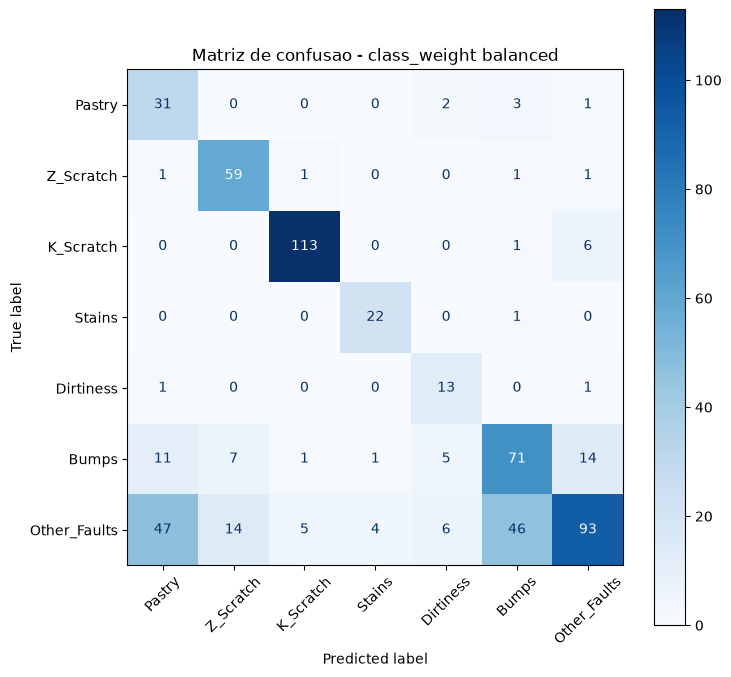

              precision    recall  f1-score   support

      Pastry       0.34      0.84      0.48        37
   Z_Scratch       0.74      0.94      0.83        63
   K_Scratch       0.94      0.94      0.94       120
      Stains       0.81      0.96      0.88        23
   Dirtiness       0.50      0.87      0.63        15
       Bumps       0.58      0.65      0.61       110
Other_Faults       0.80      0.43      0.56       215

    accuracy                           0.69       583
   macro avg       0.67      0.80      0.71       583
weighted avg       0.74      0.69      0.69       583



In [16]:
y_train_int = np.argmax(Y_train, axis=1)
classes = np.unique(y_train_int)
pesos = compute_class_weight(class_weight='balanced', classes=classes, y=y_train_int)
class_weight = dict(zip(classes, pesos))
print(class_weight)

model_cw = cria_modelo()  # rede nova, sem treino anterior
model_cw.fit(X_train, Y_train, epochs=100, batch_size=32,
             class_weight=class_weight, verbose=0)

desempenho_cw = model_cw.evaluate(X_test, Y_test, verbose=0)
print("Acuracia (class_weight): %.2f%%" % (desempenho_cw[1] * 100))

Y_pred_cw = model_cw.predict(X_test)
y_pred_cw = np.argmax(Y_pred_cw, axis=1)

cm_cw = confusion_matrix(y_true, y_pred_cw, labels=range(7))
fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_cw, display_labels=nomes_falhas)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45)
plt.title('Matriz de confusao - class_weight balanced')
plt.show()

print(classification_report(y_true, y_pred_cw, labels=range(7),
                             target_names=nomes_falhas, zero_division=0))

### (b) SMOTE
Aplicamos o SMOTE somente ao conjunto de treino, nunca ao de teste, para não contaminar a validação.

[458 458 458 458 458 458 458]


Acuracia (SMOTE): 72.56%
 1/19 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step  

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


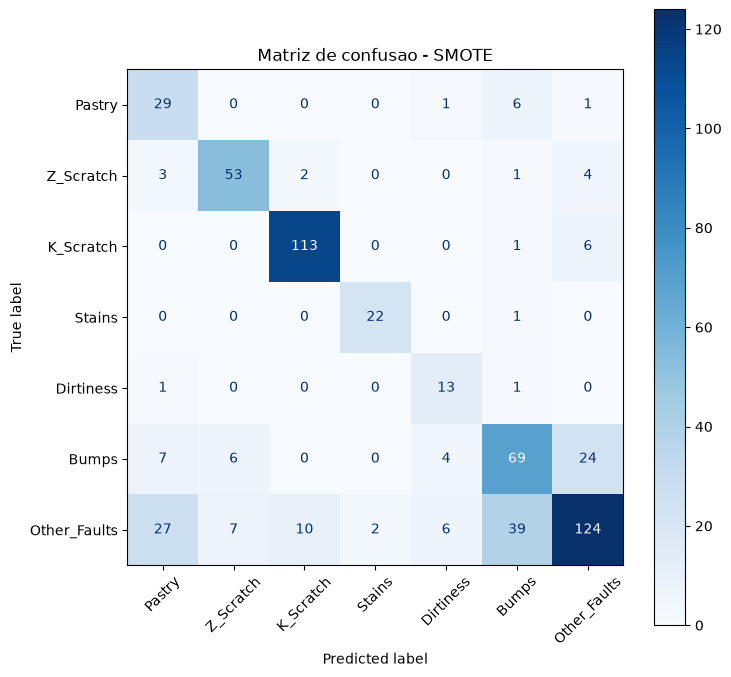

              precision    recall  f1-score   support

      Pastry       0.43      0.78      0.56        37
   Z_Scratch       0.80      0.84      0.82        63
   K_Scratch       0.90      0.94      0.92       120
      Stains       0.92      0.96      0.94        23
   Dirtiness       0.54      0.87      0.67        15
       Bumps       0.58      0.63      0.61       110
Other_Faults       0.78      0.58      0.66       215

    accuracy                           0.73       583
   macro avg       0.71      0.80      0.74       583
weighted avg       0.75      0.73      0.73       583



In [17]:
# pip install imbalanced-learn (se necessario)
y_train_int = np.argmax(Y_train, axis=1)

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train_int)
Y_train_bal = to_categorical(y_train_bal, num_classes=7)

print(np.bincount(y_train_bal))  # classes agora balanceadas

model_smote = cria_modelo()  # rede nova, sem treino anterior
model_smote.fit(X_train_bal, Y_train_bal, epochs=100, batch_size=32, verbose=0)

desempenho_smote = model_smote.evaluate(X_test, Y_test, verbose=0)
print("Acuracia (SMOTE): %.2f%%" % (desempenho_smote[1] * 100))

Y_pred_sm = model_smote.predict(X_test)
y_pred_sm = np.argmax(Y_pred_sm, axis=1)

cm_sm = confusion_matrix(y_true, y_pred_sm, labels=range(7))
fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_sm, display_labels=nomes_falhas)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45)
plt.title('Matriz de confusao - SMOTE')
plt.show()

print(classification_report(y_true, y_pred_sm, labels=range(7),
                             target_names=nomes_falhas, zero_division=0))

**Comparando as técnicas:** a tabela abaixo junta os resultados do modelo original (melhor caso), do `class_weight` e do SMOTE:

| Métrica | Original | class_weight | SMOTE |
|---|---|---|---|
| Acurácia geral | 72,38% | 68,95% | 72,56% |
| Recall `Pastry` | 0,43 | 0,84 | 0,78 |
| Recall `Bumps` | 0,21 | 0,65 | 0,63 |
| Recall `Dirtiness` | 0,73 | 0,87 | 0,87 |
| Recall `Other_Faults` | 0,89 | 0,43 | 0,58 |
| F1-score macro | 0,71 | 0,71 | 0,74 |
| F1-score weighted | 0,70 | 0,69 | 0,73 |

As duas técnicas melhoraram bastante o recall das falhas que o modelo original classificava mal: o recall de `Bumps` subiu de 0,21 para 0,65 (`class_weight`) e 0,63 (SMOTE), e o de `Pastry` subiu de 0,43 para 0,84 e 0,78. O lado ruim é que a rede passa a prever `Other_Faults` com menos frequência (recall cai de 0,89 para 0,43 no `class_weight` e 0,58 no SMOTE), porque deixa de "cair" nessa classe genérica sempre que está em dúvida.

Na acurácia geral, o `class_weight` foi o que mais perdeu (68,95%, 3,4 pontos percentuais a menos que o original), porque ele força demais a rede a acertar as classes raras (chega a usar peso 4,85 para `Dirtiness`, contra só 0,42 para `Other_Faults`), e isso acaba gerando mais erros do tipo "a rede apostou numa classe rara e errou". Já o SMOTE manteve a acurácia quase igual à original (72,56% contra 72,38%) e teve o melhor F1-score macro entre os três (0,74), ou seja, foi o que deixou o desempenho mais equilibrado entre todas as classes — porque, em vez de só mudar o peso do erro, ele cria exemplos novos (sintéticos) das classes raras para treinar a rede.

Uma ressalva sobre o SMOTE: as colunas 12 e 13 (`TypeOfSteel_A300` e `TypeOfSteel_A400`) são binárias (0 ou 1, indicando o tipo de aço da placa). Como o SMOTE cria amostras novas misturando (interpolando) amostras vizinhas, ele pode gerar valores quebrados nessas colunas, tipo 0,3 ou 0,7, que não existem na vida real. Isso não invalida a técnica — a rede ainda consegue usar esse valor como uma espécie de "chance" de ser um tipo de aço ou outro — mas é uma inconsistência que vale a pena citar, já que essas variáveis deveriam ser sempre 0 ou 1.

## Desafio 2 (opcional): redução de dimensionalidade

Aplicamos a Análise de Componentes Principais (PCA) para reduzir o número de características de entrada. O PCA é ajustado apenas com os dados de treino (já normalizados) e depois aplicado aos dados de teste, preservando o número de amostras (1941) e reduzindo a dimensão de `X` de 27 para `m` componentes, com `m <= 27`.

In [18]:
X_train_raw, X_test_raw, Y_train_pca, Y_test_pca = train_test_split(X, Y, test_size=0.30, random_state=42)

mm_pca = preprocessing.MinMaxScaler(feature_range=(0, 1))
X_train_scaled = mm_pca.fit_transform(X_train_raw)
X_test_scaled = mm_pca.transform(X_test_raw)

# Mantemos componentes principais suficientes para explicar 95% da variancia dos dados
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

m = pca.n_components_
print(f'Numero de componentes selecionados (m): {m} de 27 caracteristicas originais')
print(f'Variancia explicada acumulada: {100 * np.sum(pca.explained_variance_ratio_):.2f}%')
print('Formato de X apos o PCA:', X_train_pca.shape[0] + X_test_pca.shape[0], 'x', m)

Numero de componentes selecionados (m): 10 de 27 caracteristicas originais
Variancia explicada acumulada: 95.43%
Formato de X apos o PCA: 1941 x 10


In [19]:
model_pca = cria_modelo_mlp(camadas=int(melhor_cfg['camadas']),
                            neuronios=int(melhor_cfg['neuronios']),
                            ativacao=melhor_cfg['ativacao'],
                            otimizador=melhor_cfg['otimizador'],
                            taxa_aprendizado=melhor_cfg['taxa_aprendizado'],
                            input_dim=m)
model_pca.fit(X_train_pca, Y_train_pca, epochs=100, batch_size=32, verbose=0)

desempenho_pca = model_pca.evaluate(X_test_pca, Y_test_pca, verbose=0)
print(f'Acuracia com PCA (m={m} componentes)        : {desempenho_pca[1] * 100:.2f}%')
print(f'Acuracia com as 27 caracteristicas originais : {desempenho_melhor[1] * 100:.2f}%')

Acuracia com PCA (m=10 componentes)        : 74.96%
Acuracia com as 27 caracteristicas originais : 72.38%


**Resposta:** o PCA reduziu a base de 27 para só **10 componentes principais**, mantendo 95,43% da variância dos dados — ou seja, menos da metade das variáveis originais já foi suficiente para guardar quase toda a informação importante da base. Isso faz sentido porque várias das 27 características são derivadas umas das outras (por exemplo, `Log_X_Index` e `Log_Y_Index` são o logaritmo de outras colunas, e `LogOfAreas`/`SigmoidOfAreas` vêm de `Pixels_Areas`), ou seja, há bastante informação repetida entre elas.

Usando a mesma divisão treino/teste (mesma semente aleatória) e a mesma configuração de rede (melhor caso da Questão 4), a acurácia com os 10 componentes do PCA (74,96%) ficou, surpreendentemente, **melhor** do que com as 27 características originais (72,38%) — quase 2,6 pontos percentuais a mais, usando menos da metade das variáveis de entrada. Uma explicação possível é que o PCA, além de reduzir o número de variáveis, também remove parte do ruído e da repetição de informação entre colunas muito parecidas; com um conjunto de treino pequeno (só 1358 amostras), uma rede com menos variáveis de entrada tem menos chance de "decorar" relações que não são realmente importantes.

A desvantagem do PCA é que ele mistura as 27 variáveis originais em combinações lineares, então perdemos a possibilidade de explicar o resultado usando as variáveis originais — não dá mais para dizer, por exemplo, "esta falha foi classificada como `Bumps` porque a área do defeito é grande". Em uma aplicação real de controle de qualidade, isso pode ser uma desvantagem, já que entender a causa física de cada defeito também é importante, e não só acertar a classificação.

## Conclusões

Neste projeto treinamos uma rede neural MLP no Keras para identificar os 7 tipos de falha em placas de aço, usando 27 características geométricas de cada defeito. Seguimos o caminho completo de um projeto de aprendizado supervisionado: preparar os dados (separar treino/teste e normalizar), testar diferentes configurações de rede, avaliar com acurácia, matriz de confusão e relatório de classificação, e por fim perceber que a base de dados usada é desbalanceada entre as classes.

Os testes mostraram que mudar os parâmetros da rede (camadas, neurônios, ativação, otimizador e taxa de aprendizado) realmente muda o desempenho, e às vezes bastante, como no caso do otimizador SGD, que teve o pior resultado de todos. Também vimos que a acurácia geral pode esconder problemas, mas não necessariamente do jeito que a gente esperava: o modelo acertou muito bem falhas raras como `Stains` e `Dirtiness`, mas classificou muito mal `Bumps`, uma falha bem comum na base, confundindo-a quase sempre com `Other_Faults`. Ou seja, o problema não foi só a quantidade de amostras de cada classe, mas também o quanto cada tipo de falha "se parece" com a categoria `Other_Faults`. As técnicas `class_weight` e SMOTE ajudaram a melhorar bastante o recall das falhas mal classificadas (`Pastry` e `Bumps`), com uma pequena perda de acurácia geral no caso do `class_weight`, e quase nenhuma perda no caso do SMOTE. Por fim, reduzir as 27 características para só 10 componentes principais com o PCA não só manteve como até melhorou um pouco o desempenho de classificação, mostrando que várias das 27 variáveis originais eram redundantes entre si.